# Thumbnail DINO To Embedding Atlas

This notebook takes a thumbnail config exported from `thumbnail_explorer_app.py`, rebuilds the exact same thumbnail dataset, computes frozen DINOv2 features, saves thumbnail PNGs plus metadata, computes a 2D projection and nearest neighbors, and prepares a dataframe for `EmbeddingAtlasWidget`.

The projection is computed from image embeddings, not from the text description.

In [64]:
import sys
from pathlib import Path

sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import os

from movebench.thumbnail_config import load_thumbnail_generation_config, thumbnail_config_run_slug
from movebench.thumbnail_atlas import (
    
    build_atlas_dataframe,
    build_thumbnail_metadata,
    save_atlas_artifacts,
    save_thumbnail_pngs,
    serialize_neighbors,
)
from movebench.thumbnail_embedding import compute_neighbors, compute_thumbnail_embeddings, project_embeddings

In [65]:
import torch
torch.cuda.is_available()

True

In [96]:
# Point this to a config exported from the Streamlit thumbnail explorer.
CONFIG_PATH = Path('/data/vision/beery/scratch/shir/codes/movebench/configs/thumbnails/Carter_28708a9c_raw_merged_labeled_outliers__all__thumbnail_config.json')

# Output root for thumbnails, metadata, and embeddings.
OUTPUT_ROOT = Path('/data/vision/beery/scratch/shir/results/thumbnail_atlas/',os.path.basename(CONFIG_PATH).split('.')[0])

EMBEDDING_CONFIG = {
    'model_name': 'dinov2_vits14',
    'device_preference': 'cuda',
    'batch_size': 32,
    'image_size': 224,
    'extra_features': ['extent_x_m','extent_y_m']
}

PROJECTION_CONFIG = {
    'method': 'pca',
    'random_state': 17,
    'n_neighbors': 20,
    'min_dist': 0.10,
    'perplexity': 30.0,
}

In [97]:
np.quantile(embeddings[:,-1],0.95), embeddings[:,-1].max()

(0.7164992690086355, 35.761974)

In [108]:
config = load_thumbnail_generation_config(CONFIG_PATH)
#config['data']['individual_id'] = 'Moe'
config['thumbnail']['scale_mode'] = 'chunk'
config['thumbnail']['chunk_size']=15
config['thumbnail']['color_by'] = 'iforest_anomaly_score'

config['embedding'] = {
    **config.get('embedding', {}),
    **EMBEDDING_CONFIG,
}


config['projection'] = PROJECTION_CONFIG
run_slug = thumbnail_config_run_slug(config)
run_dir = OUTPUT_ROOT / run_slug
run_dir.mkdir(parents=True, exist_ok=True)

config, build, metadata = build_thumbnail_metadata(config)
print(f'Loaded config for {config["data"]["csv_path"]}')
print(f'Thumbnails: {len(build.images):,}')
print(f'Individuals: {metadata["individual_id"].astype(str).nunique():,}')
metadata.head()

Loaded config for /data/vision/beery/scratch/shir/codes/movebench/notebooks/Carter_28708a9c_raw_merged_labeled_outliers.csv
Thumbnails: 6,370
Individuals: 22


,global_chunk_idx,individual_id,chunk_idx,split,start_time,end_time,n_fixes,start_lon,start_lat,end_lon,...,has_any_outlier,outlier_frac,clean,source_name,csv_path,selected_split,selected_individual_id,overlap_state,thumbnail_id,description
0,0,Ada,0,None,2016-07-31 14:00:37,2016-07-31 18:20:39,15,141.044717,-33.134447,141.041911,...,False,0.000000,True,Carter_28708a9c_raw_merged_labeled_outliers,/data/vision/beery/scratch/shir/codes/movebenc...,all,None,clean,Carter_28708a9c_raw_merged_labeled_outliers|No...,source=Carter_28708a9c_raw_merged_labeled_outl...
1,1,Ada,1,None,2016-07-31 18:40:38,2016-08-01 00:36:44,15,141.042139,-33.140197,141.043550,...,False,0.000000,True,Carter_28708a9c_raw_merged_labeled_outliers,/data/vision/beery/scratch/shir/codes/movebenc...,all,None,clean,Carter_28708a9c_raw_merged_labeled_outliers|No...,source=Carter_28708a9c_raw_merged_labeled_outl...
2,2,Ada,2,None,2016-08-01 02:12:45,2016-08-02 07:20:37,15,141.043439,-33.138617,141.082169,...,False,0.000000,True,Carter_28708a9c_raw_merged_labeled_outliers,/data/vision/beery/scratch/shir/codes/movebenc...,all,None,clean,Carter_28708a9c_raw_merged_labeled_outliers|No...,source=Carter_28708a9c_raw_merged_labeled_outl...
3,3,Ada,3,None,2016-08-02 07:40:39,2016-08-02 12:20:37,15,141.084481,-33.132889,141.102094,...,False,0.000000,True,Carter_28708a9c_raw_merged_labeled_outliers,/data/vision/beery/scratch/shir/codes/movebenc...,all,None,clean,Carter_28708a9c_raw_merged_labeled_outliers|No...,source=Carter_28708a9c_raw_merged_labeled_outl...
4,4,Ada,4,None,2016-08-02 12:40:37,2016-08-03 08:40:37,15,141.101219,-33.114400,141.106297,...,True,0.133333,False,Carter_28708a9c_raw_merged_labeled_outliers,/data/vision/beery/scratch/shir/codes/movebenc...,all,None,algorithm only,Carter_28708a9c_raw_merged_labeled_outliers|No...,source=Carter_28708a9c_raw_merged_labeled_outl...


In [109]:
any_outlier_summary = pd.DataFrame(
    {
        'chunks_with_any_outlier': [int(metadata['has_any_outlier'].fillna(False).astype(bool).sum())],
        'flagged_fixes_any_outlier': [int(metadata['n_outlier_fixes'].sum())],
        'total_chunks': [int(len(metadata))],
        'total_fixes': [int(metadata['n_fixes'].sum())],
    },
    index=['any_outlier'],
)
any_outlier_summary


,chunks_with_any_outlier,flagged_fixes_any_outlier,total_chunks,total_fixes
any_outlier,790,1249,6370,95413


In [110]:
thumbnail_paths = save_thumbnail_pngs(build.images, metadata, out_dir=run_dir / 'thumbnails')
metadata = metadata.copy()
metadata['thumbnail_path'] = thumbnail_paths
metadata[['thumbnail_id', 'thumbnail_path', 'description']].head()

,thumbnail_id,thumbnail_path,description
0,Carter_28708a9c_raw_merged_labeled_outliers|No...,/data/vision/beery/scratch/shir/results/thumbn...,source=Carter_28708a9c_raw_merged_labeled_outl...
1,Carter_28708a9c_raw_merged_labeled_outliers|No...,/data/vision/beery/scratch/shir/results/thumbn...,source=Carter_28708a9c_raw_merged_labeled_outl...
2,Carter_28708a9c_raw_merged_labeled_outliers|No...,/data/vision/beery/scratch/shir/results/thumbn...,source=Carter_28708a9c_raw_merged_labeled_outl...
3,Carter_28708a9c_raw_merged_labeled_outliers|No...,/data/vision/beery/scratch/shir/results/thumbn...,source=Carter_28708a9c_raw_merged_labeled_outl...
4,Carter_28708a9c_raw_merged_labeled_outliers|No...,/data/vision/beery/scratch/shir/results/thumbn...,source=Carter_28708a9c_raw_merged_labeled_outl...


In [111]:
embeddings, embedding_info = compute_thumbnail_embeddings(build.images, 
                                                          embedding_config=EMBEDDING_CONFIG,   metadata=metadata,)
projection, projection_info, projection_warnings = project_embeddings(
    embeddings,
    projection_config=PROJECTION_CONFIG,
    cache_root=run_dir / '.cache',
)
neighbor_idx, neighbor_dist = compute_neighbors(embeddings)
neighbors = serialize_neighbors(
    neighbor_idx,
    metadata['thumbnail_id'].astype(str).tolist(),
    neighbor_distances=neighbor_dist,
)

print('Embedding info:', embedding_info)
print('Projection info:', projection_info)
if projection_warnings:
    print('Projection warnings:')
    for warning in projection_warnings:
        print('-', warning)
embeddings.shape, projection.shape

Embedding info: {'device': 'cuda', 'model_name': 'dinov2_vits14', 'image_size': 224, 'batch_size': 32, 'feature_source': 'cls_token', 'intermediate_layer_offset': 2, 'cudnn_enabled': True, 'extra_features': ['extent_x_m', 'extent_y_m'], 'extra_feature_stats': [{'name': 'extent_x_m', 'mean': 2037.7645006730313, 'std': 8266.107102901608, 'n_finite': 6370, 'status': 'zscore'}, {'name': 'extent_y_m', 'mean': 1711.0812132684434, 'std': 3243.8244133500575, 'n_finite': 6370, 'status': 'zscore'}], 'base_embedding_dim': 384, 'output_dim': 386}
Projection info: {'method': 'pca'}


((6370, 386), (6370, 2))

In [112]:
atlas_df = build_atlas_dataframe(
    metadata,
    projection=projection,
    neighbors=neighbors,
    thumbnail_paths=thumbnail_paths,
)

# save_atlas_artifacts(
#     config=config,
#     atlas_df=atlas_df,
#     embeddings=embeddings,
#     out_root=OUTPUT_ROOT,
# )

atlas_df[['thumbnail_id', 'individual_id', 'split', 'overlap_state', 'projection_x', 'projection_y', 'neighbors']].head()

,thumbnail_id,individual_id,split,overlap_state,projection_x,projection_y,neighbors
0,Carter_28708a9c_raw_merged_labeled_outliers|No...,Ada,None,clean,-0.363947,0.119269,{'ids': ['Carter_28708a9c_raw_merged_labeled_o...
1,Carter_28708a9c_raw_merged_labeled_outliers|No...,Ada,None,clean,-0.490739,0.170896,{'ids': ['Carter_28708a9c_raw_merged_labeled_o...
2,Carter_28708a9c_raw_merged_labeled_outliers|No...,Ada,None,clean,0.077264,0.196782,{'ids': ['Carter_28708a9c_raw_merged_labeled_o...
3,Carter_28708a9c_raw_merged_labeled_outliers|No...,Ada,None,clean,-0.049463,0.036342,{'ids': ['Carter_28708a9c_raw_merged_labeled_o...
4,Carter_28708a9c_raw_merged_labeled_outliers|No...,Ada,None,algorithm only,-0.138234,-0.075416,{'ids': ['Carter_28708a9c_raw_merged_labeled_o...


In [113]:
label_cols = sorted(c for c in atlas_df.columns if c.startswith('has_'))
print('Available chunk-level label columns:')
for col in label_cols:
    print(f'- {col}')

required_label_cols = ['has_system_outlier', 'has_speed_outlier']
missing_label_cols = [col for col in required_label_cols if col not in label_cols]
if missing_label_cols:
    raise KeyError(
        'Missing required chunk-level label columns: '
        f"{missing_label_cols}. Available has_* columns: {label_cols}"
    )

summary_rows = []
for label_col in ['has_any_outlier'] + label_cols:
    fix_count_col = 'n_outlier_fixes' if label_col == 'has_any_outlier' else f"n_{label_col[4:]}"
    summary_rows.append(
        {
            'label_col': label_col,
            'chunks_with_label': int(atlas_df[label_col].fillna(False).astype(bool).sum()),
            'flagged_fixes': int(atlas_df[fix_count_col].sum()) if fix_count_col in atlas_df.columns else None,
        }
    )
label_summary = pd.DataFrame(summary_rows).drop_duplicates(subset=['label_col']).set_index('label_col')
print()
print('Chunk-level vs fix-level label counts:')
display(label_summary)
print('`has_*` columns count chunks. `n_*` columns count flagged fixes within chunks.')

system_mask = atlas_df['has_system_outlier'].fillna(False).astype(bool).to_numpy()
speed_mask = atlas_df['has_speed_outlier'].fillna(False).astype(bool).to_numpy()
combined_labels = np.full(len(atlas_df), 'neither', dtype=object)
combined_labels[system_mask &
                
                 ~speed_mask] = 'system only'
combined_labels[~system_mask & speed_mask] = 'speed only'
combined_labels[system_mask & speed_mask] = 'both'
combined_counts = (
    pd.Series(combined_labels, name='system_speed_category')
    .value_counts()
    .reindex(['neither', 'system only', 'speed only', 'both'], fill_value=0)
    .rename_axis('label')
    .to_frame('n_chunks')
)
print()
print('Combined system/speed category counts (chunk-level):')
display(combined_counts)


Available chunk-level label columns:
- has_algorithm_marked_outlier
- has_any_outlier
- has_manually_marked_outlier
- has_speed_outlier
- has_system_outlier

Chunk-level vs fix-level label counts:


,chunks_with_label,flagged_fixes
label_col,,
has_any_outlier,790,1249
has_algorithm_marked_outlier,774,1216
has_manually_marked_outlier,9,10
has_speed_outlier,34,48
has_system_outlier,774,1216


`has_*` columns count chunks. `n_*` columns count flagged fixes within chunks.

Combined system/speed category counts (chunk-level):


,n_chunks
label,
neither,5583
system only,753
speed only,13
both,21


In [114]:
import matplotlib.pyplot as plt


def available_thumbnail_label_columns(df: pd.DataFrame) -> list[str]:
    return sorted(c for c in df.columns if c.startswith('has_'))


def _coerce_label_mask(series: pd.Series) -> np.ndarray:
    return series.fillna(False).astype(bool).to_numpy()


def plot_embedding_label_scatter(
    df: pd.DataFrame,
    label_col: str,
    *,
    x: str = 'projection_x',
    y: str = 'projection_y',
    ax=None,
) -> None:
    available = available_thumbnail_label_columns(df)
    if label_col not in df.columns:
        raise KeyError(
            f"{label_col!r} not found. Available has_* columns: {available}"
        )

    mask = _coerce_label_mask(df[label_col])
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))

    ax.scatter(
        df.loc[~mask, x],
        df.loc[~mask, y],
        c='#94a3b8',
        s=18,
        alpha=0.35,
        linewidths=0,
        label='false',
    )
    ax.scatter(
        df.loc[mask, x],
        df.loc[mask, y],
        c='#d26531',
        s=28,
        alpha=0.9,
        linewidths=0.4,
        edgecolors='white',
        label='true',
    )
    ax.set_title(label_col.replace('_', ' '))
    ax.set_xlabel(x.replace('_', ' '))
    ax.set_ylabel(y.replace('_', ' '))
    ax.legend(title='label', frameon=False)


def system_speed_category(df: pd.DataFrame) -> pd.Categorical:
    required = ['has_system_outlier', 'has_speed_outlier']
    available = available_thumbnail_label_columns(df)
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise KeyError(
            'Missing required chunk-level label columns: '
            f"{missing}. Available has_* columns: {available}"
        )

    system_mask = _coerce_label_mask(df['has_system_outlier'])
    speed_mask = _coerce_label_mask(df['has_speed_outlier'])
    labels = np.full(len(df), 'neither', dtype=object)
    labels[system_mask & ~speed_mask] = 'system only'
    labels[~system_mask & speed_mask] = 'speed only'
    labels[system_mask & speed_mask] = 'both'
    return pd.Categorical(labels, categories=['neither', 'system only', 'speed only', 'both'], ordered=True)


def plot_system_speed_comparison(
    df: pd.DataFrame,
    *,
    x: str = 'projection_x',
    y: str = 'projection_y',
    ax=None,
) -> None:
    categories = system_speed_category(df)
    palette = {
        'neither': '#94a3b8',
        'system only': '#2563eb',
        'speed only': '#d97706',
        'both': '#b91c1c',
    }
    sizes = {
        'neither': 18,
        'system only': 26,
        'speed only': 26,
        'both': 34,
    }
    alphas = {
        'neither': 0.28,
        'system only': 0.78,
        'speed only': 0.78,
        'both': 0.92,
    }
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))

    for label in categories.categories:
        mask = categories == label
        ax.scatter(
            df.loc[mask, x],
            df.loc[mask, y],
            c=palette[label],
            s=sizes[label],
            alpha=alphas[label],
            linewidths=0.4 if label == 'both' else 0,
            edgecolors='white' if label == 'both' else 'none',
            label=label,
        )

    ax.set_title('system vs speed outlier overlap')
    ax.set_xlabel(x.replace('_', ' '))
    ax.set_ylabel(y.replace('_', ' '))
    ax.legend(title='category', frameon=False)


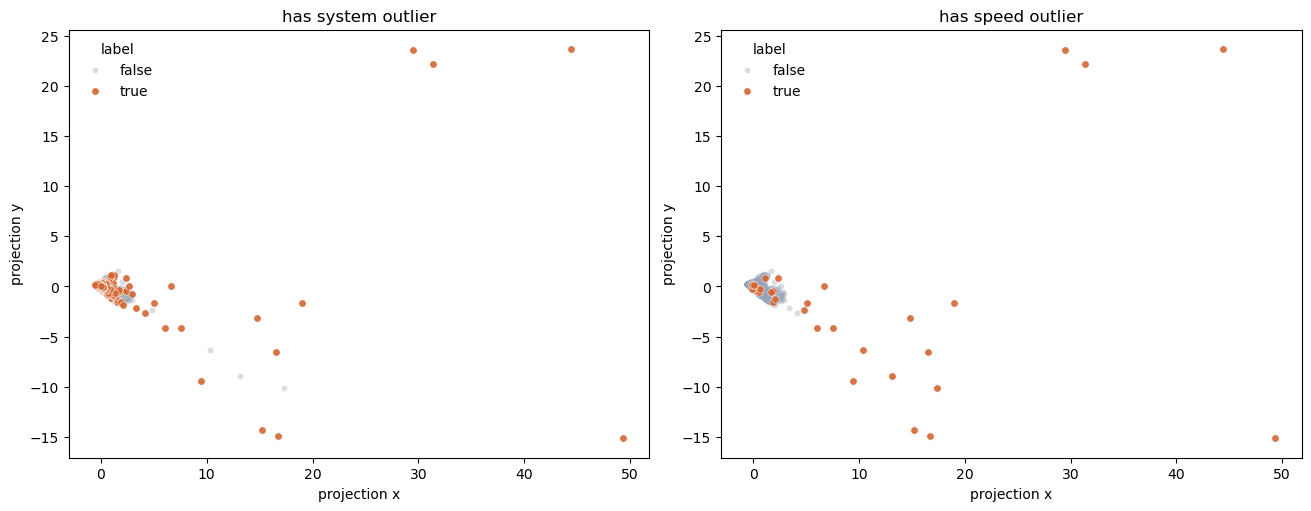

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, label_col in zip(axes, ['has_system_outlier', 'has_speed_outlier']):
    plot_embedding_label_scatter(atlas_df, label_col, ax=ax)
plt.show()


,n_chunks
label,
neither,5583
system only,753
speed only,13
both,21


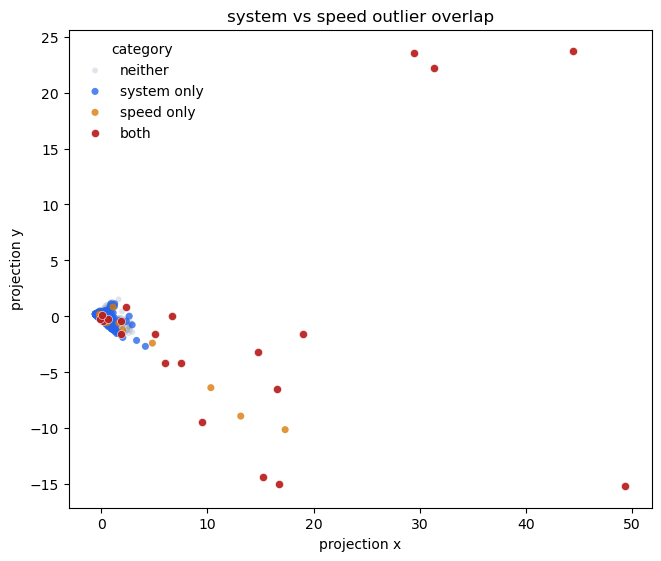

In [116]:
atlas_df = atlas_df.copy()
atlas_df['system_speed_category'] = system_speed_category(atlas_df)
combined_counts = (
    atlas_df['system_speed_category']
    .value_counts()
    .reindex(['neither', 'system only', 'speed only', 'both'], fill_value=0)
    .rename_axis('label')
    .to_frame('n_chunks')
)
display(combined_counts)

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
plot_system_speed_comparison(atlas_df, ax=ax)
plt.show()


In [117]:
from embedding_atlas.widget import EmbeddingAtlasWidget

widget = EmbeddingAtlasWidget(
    atlas_df,
    text='description',
    x='projection_x',
    y='projection_y',
    neighbors='neighbors',
)
widget

In [ ]:
fake_build = np.concatenate([])

In [71]:
## Fake embeddings to sanity check the pipeline:
fake_embeddings, fake_embedding_info = compute_thumbnail_embeddings(fake_build,#build.images, 
                                                          embedding_config=EMBEDDING_CONFIG)
fake_projection, fake_projection_info, fake_projection_warnings = project_embeddings(
    fake_embeddings,
    projection_config=PROJECTION_CONFIG,
    cache_root=run_dir / '.cache',
)
fake_neighbor_idx, fake_neighbor_dist = compute_neighbors(fake_embeddings)
fake_neighbors = serialize_neighbors(
    fake_neighbor_idx,
    fake_metadata['thumbnail_id'].astype(str).tolist(),
    neighbor_distances=fake_neighbor_dist,
)

print('Embedding info:', fake_embedding_info)
print('Projection info:', fake_projection_info)
if fake_projection_warnings:
    print('Projection warnings:')
    for warning in fake_projection_warnings:
        print('-', warning)
fake_embeddings.shape, fake_projection.shape

/data/vision/beery/scratch/shir/micromamba/envs/movebench-torch/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Embedding info: {'device': 'cuda', 'model_name': 'dinov2_vits14', 'image_size': 224, 'batch_size': 32, 'cudnn_enabled': True}
Projection info: {'method': 'umap'}


((1919, 384), (1919, 2))

In [80]:
fake_metadata['has_ones']=fake_metadata['labels']=='ones'
fake_atlas_df = build_atlas_dataframe(
    fake_metadata,
    projection=fake_projection,
    neighbors=fake_neighbors,
    thumbnail_paths=['']*1919#thumbnail_paths,
)


In [81]:
widget = EmbeddingAtlasWidget(
    fake_atlas_df,
    text='description',
    x='projection_x',
    y='projection_y',
    neighbors='neighbors',
)
widget

In [76]:
fake_metadata

,labels,thumbnail_id
0,ones,0
1,ones,1
2,ones,2
3,ones,3
4,ones,4
...,...,...
1914,zeros,1914
1915,zeros,1915
1916,zeros,1916
1917,zeros,1917


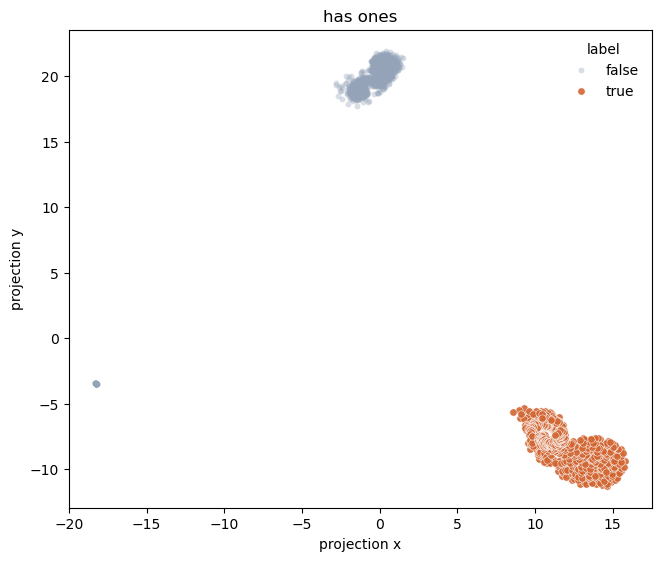

In [82]:

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
plot_embedding_label_scatter(fake_atlas_df, 'has_ones', ax=ax)
plt.show()

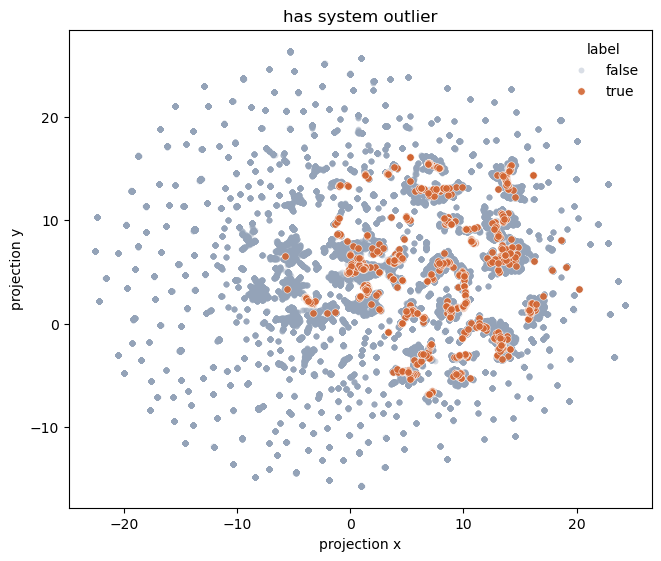

In [95]:

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
plot_embedding_label_scatter(atlas_df, 'has_system_outlier', ax=ax)
plt.show()

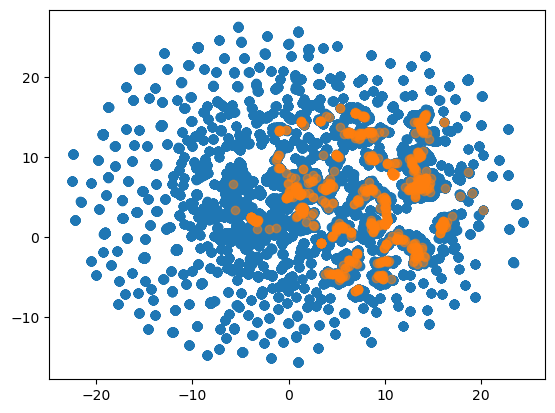

In [96]:
plt.scatter(atlas_df[~atlas_df.has_system_outlier]['projection_x'],atlas_df[~atlas_df.has_system_outlier]['projection_y'])
plt.scatter(atlas_df[atlas_df.has_system_outlier]['projection_x'],atlas_df[atlas_df.has_system_outlier]['projection_y'],alpha=0.5)